<a href="https://colab.research.google.com/github/anashenkonina-collab/python_for_ds_task/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%22HW_11_1_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Pandas_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
df = pd.read_csv('yulu_bike_sharing_dataset.csv')

In [4]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [6]:
df.shape

(10886, 19)

Набір даних містить 10 886 рядків (записів) та 19 колонок


In [7]:
df

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-12-19 19:00:00,4,0,1,1,15.58,19.695,50,26.0027,7,329,336,2012-12-19,19,51,2,Wednesday,2012,12,19
2012-12-19 20:00:00,4,0,1,1,14.76,17.425,57,15.0013,10,231,241,2012-12-19,19,51,2,Wednesday,2012,12,20
2012-12-19 21:00:00,4,0,1,1,13.94,15.910,61,15.0013,4,164,168,2012-12-19,19,51,2,Wednesday,2012,12,21


Дані мають погодинну деталізацію. Як видно з виведеної таблиці df(стовпчик datetime), кожен рядок містить агреговану інформацію про погодні умови та кількість орендованих велосипедів за одну конкретну годину

## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


In [10]:
daily_rentals = df['count'].resample('D').sum()

daily_rentals.head()

,count
datetime,
2011-01-01,985
2011-01-02,801
2011-01-03,1349
2011-01-04,1562
2011-01-05,1600


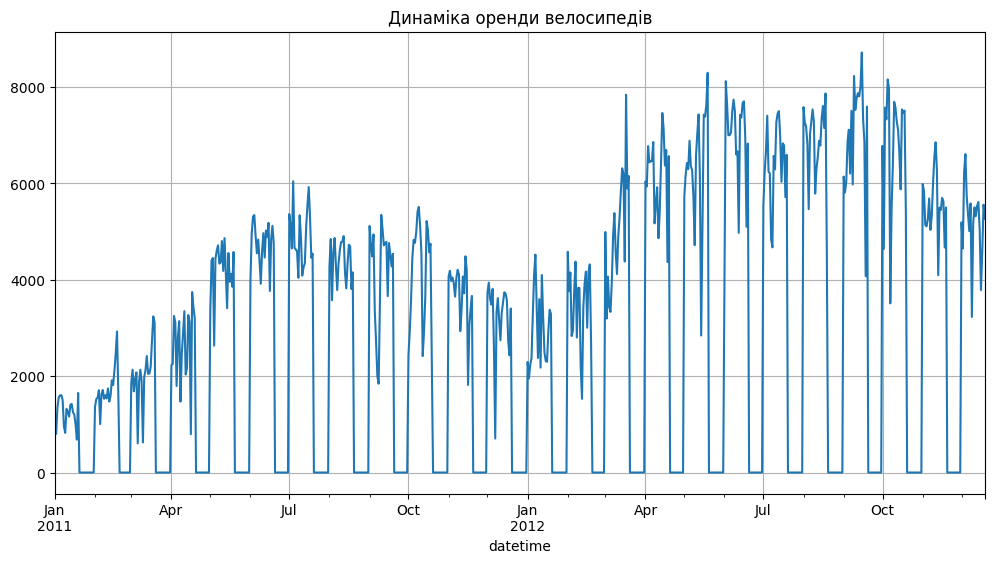

In [15]:
daily_rentals.plot(
    figsize=(12, 6),
    title='Динаміка оренди велосипедів',
    grid=True
    );

In [19]:
print(df['day'].unique())


[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]


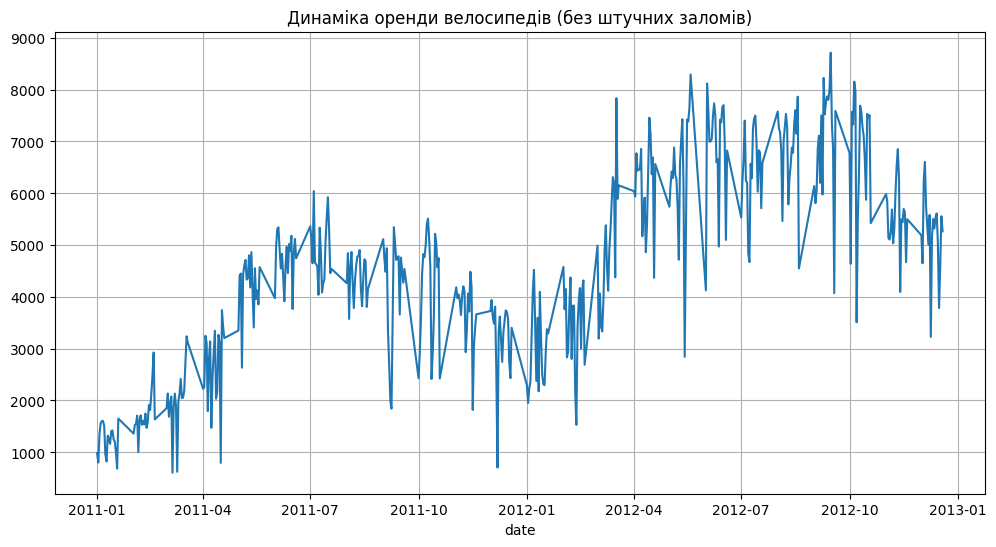

In [18]:
daily_rentals_clean = df.groupby('date')['count'].sum()

daily_rentals_clean.plot(
    figsize=(12, 6),
    title='Динаміка оренди велосипедів (без штучних заломів)',
    grid=True
);


1. В наборі даних, дані про оренду є лише за перші 19 днів кожного місяця . Дні з 20 по 31 число відсутні. ФункціЯ resample('D'), автоматично рахує суму за пропущені дні (з 20 по 31 число), вона дорівнює 0, через це лінія на графіку щомісяця різко падає на саме дно, утворюючи «заломи». Потрібно згрупувати дані нашої створеної раніше колонки dateчерез метод groupby('date'), тоді відсутні дані(дати) будуть проігноровані, і не буде "заломів".

2. На графіку видно тенденцію росту користувачів за рік, тобто ріст бізнесу.

3. На графіку яскраво виражена сезонність: спади (зима / початок року) -найменші показники; піки (літо / осінь) - найвищий попит

4. На графіку помітні аномально низькі та високі значення. Думаю, що це пов'язано з погодними умовами даного регіону


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

In [24]:
india_seasons_mapping = {
    12: 1, 1: 1, 2: 1,
    3: 2, 4: 2, 5: 2,
    6: 3, 7: 3, 8: 3, 9: 3,
    10: 4, 11: 4
}

df['weather_season_india'] = df['month'].map(india_seasons_mapping)

df[['month', 'weather_season_india']].sample(10)

,month,weather_season_india
datetime,,
2011-07-18 10:00:00,7,3
2011-10-13 09:00:00,10,4
2011-01-11 10:00:00,1,1
2012-08-03 16:00:00,8,3
2011-01-14 07:00:00,1,1
2011-03-03 09:00:00,3,2
2012-06-19 03:00:00,6,3
2012-11-14 20:00:00,11,4
2011-06-08 19:00:00,6,3


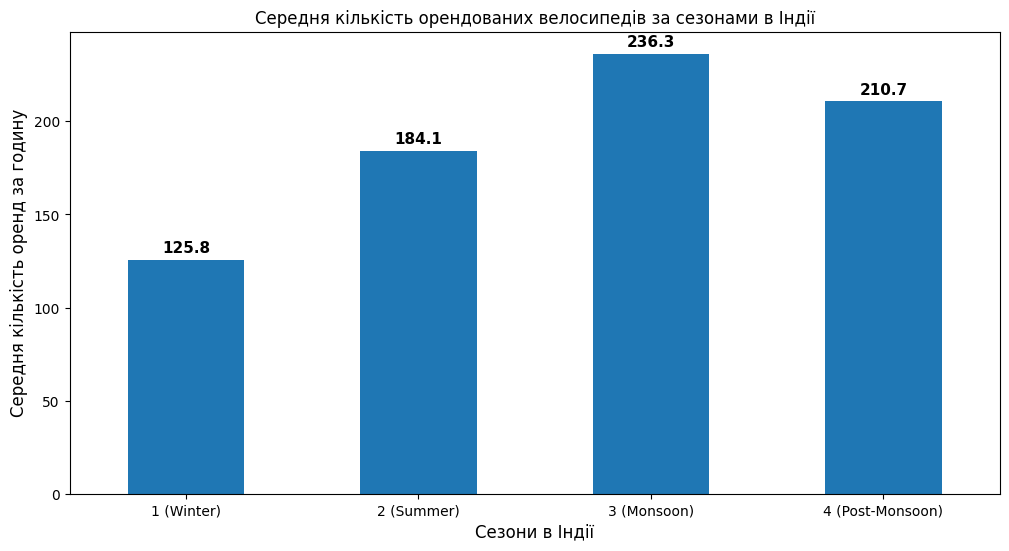

In [35]:
rentals_season = df.groupby('weather_season_india')['count'].mean()
rentals_season.index = ['1 (Winter)', '2 (Summer)', '3 (Monsoon)', '4 (Post-Monsoon)']
ax = rentals_season.plot.bar(
    figsize=(12, 6),
    title='Середня кількість орендованих велосипедів за сезонами в Індії',
    rot=0
)
ax.set_xlabel('Сезони в Індії', fontsize=12)
ax.set_ylabel('Середня кількість оренд за годину', fontsize=12)

ax.bar_label(ax.containers[0], fmt='%.1f', padding=3, fontsize=11, fontweight='bold');


1. Найбільша середня кількість орендованих велосипедів спостерігається у 3-й сезон — Monsoon
2. Сезон мусонів в Індії припадає на літні місяці (червень–вересень). Попри дощі, це найтепліший період року з високою діловою та туристичною активністю. Другим за популярністю є Post-Monsoon (осінь), коли погода стає максимально комфортною та сухою для поїздок. Найнижчий попит — у Winter (зима), оскільки в деяких регіонах стає значно прохолодніше.
3. Оренда у найпопулярнішому сезоні (Monsoon) відрізняється від найменш популярного (Winter) приблизно у 2 рази (попит зростає вдвічі)

## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


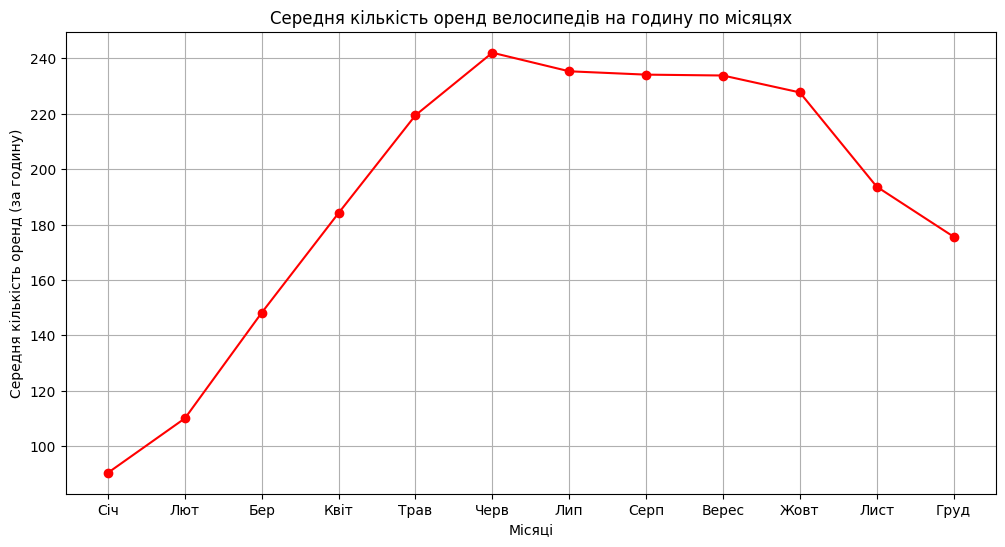

In [51]:
rentals_month = df.groupby('month')['count'].mean()

ax = rentals_month.plot(
    figsize=(12, 6),
    marker='o',
    color='red',
    grid=True,
    title='Середня кількість оренд велосипедів на годину по місяцях'
)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Січ', 'Лют', 'Бер', 'Квіт', 'Трав', 'Черв', 'Лип', 'Серп', 'Верес', 'Жовт', 'Лист', 'Груд'])

ax.set_xlabel('Місяці')
ax.set_ylabel('Середня кількість оренд (за годину)');

1. Пік: найвищий попит (пік) спостерігається у червні (6-й місяць), Спад: найнижча точка (спад) припадає на січень (1-й місяць)
2. Так, повністю збігається. У попередньому завданні ми бачили найвищі стовпчики для сезону Monsoon (літо/рання осінь), що прямо відповідає червню–вересню на цьому графіку. Найнижчий стовпчик був у Winter (зима), що відповідає провалу в січні та лютому.
3. Клімат є ключовим фактором. Взимку (січень, лютий) прохолодна погода знижує бажання людей користуватися двоколісним транспортом. Навесні (березень–травень) з потеплінням графік стрімко йде вгору. Літній мусонний клімат Індії (червень–вересень) приносить тепло, яке тримає попит на максимумі, попри періодичні зливи. Наприкінці осені (листопад, грудень) температура знову падає, спричиняючи поступове зниження попиту.

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

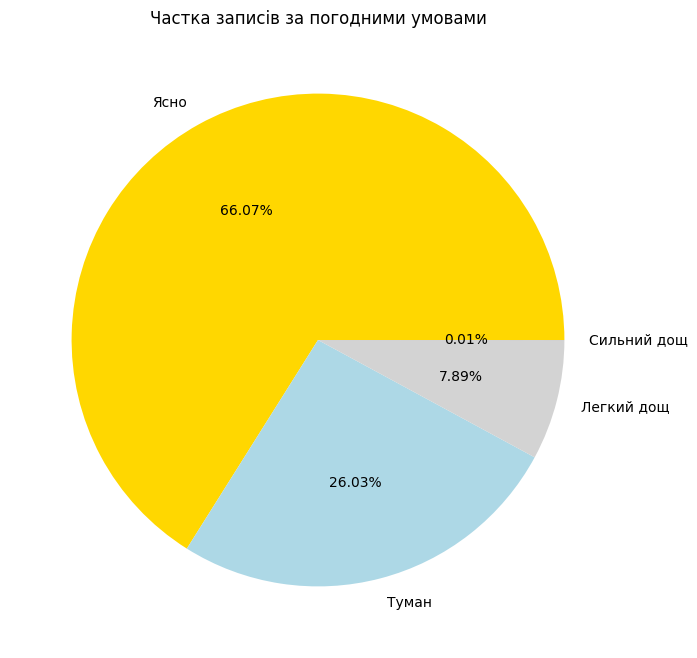

In [61]:
weather_count = df.groupby('weather')['count'].count()
weather_count

,count
weather,
1,7192
2,2834
3,859
4,1


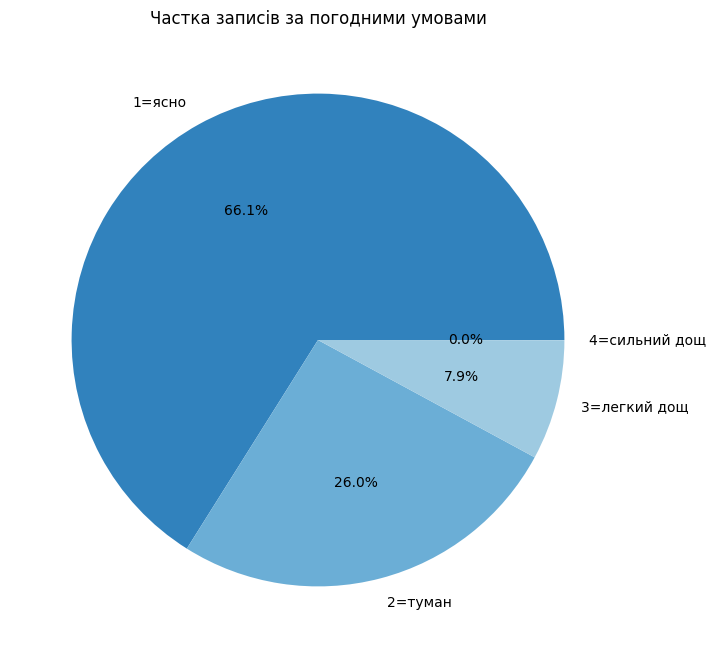

In [65]:
weather_count.plot.pie(
    figsize=(8, 8),
    autopct='%1.1f%%',
    colors=plt.cm.tab20c.colors,
    labels=['1=ясно', '2=туман', '3=легкий дощ', '4=сильний дощ'],
    title='Частка записів за погодними умовами',
    ylabel='',
);

1. Переважає ясна погода або з невеликою хмарністю (категорія 1). Вона займає 66.1% від усіх записів (7 192 години).
2. Так, але вкрай мало. Зафіксовано лише 1 такий запис (година), що становить 0.01% від загального обсягу даних.
3. Сприятлива погода (ясно та туман/хмарно) забезпечує стабільний високий попит. Опади (дощ/сніг) трапляються рідко, але вони спричиняють різке тимчасове падіння кількості оренд.

## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

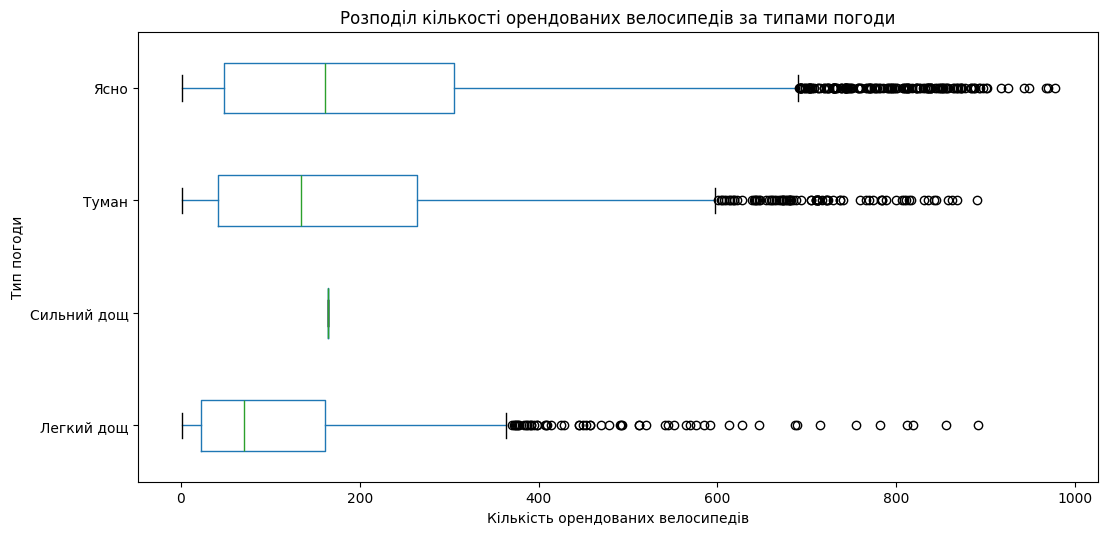

In [71]:
weather_names = {1: 'Ясно', 2: 'Туман', 3: 'Легкий дощ', 4: 'Сильний дощ'}
df['weather_label'] = df['weather'].map(weather_names)

df.boxplot(
    column='count',
    by='weather_label',
    figsize=(12, 6),
    grid=False,
    vert=False
)
plt.title('Розподіл кількості орендованих велосипедів за типами погоди')
plt.ylabel('Тип погоди')
plt.xlabel('Кількість орендованих велосипедів')
plt.suptitle('')  # Прибирає автоматичний заголовок
plt.show()

1. Найбільший розкид у кількості оренди спостерігається за погоди "Ясно" (прямокутний "ящик" найширший, а його праві "вуса" тягнуться далі за інші — майже до 700 оренд за годину)
2. Так, велика кількість викидів присутня за погоди "Ясно", "Туман" та "Легкий дощ". Особливо багато екстремальних викидів.
3. Найвище медіанне значення спостерігається за погоди "Ясно" (вона знаходиться найправіше).

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

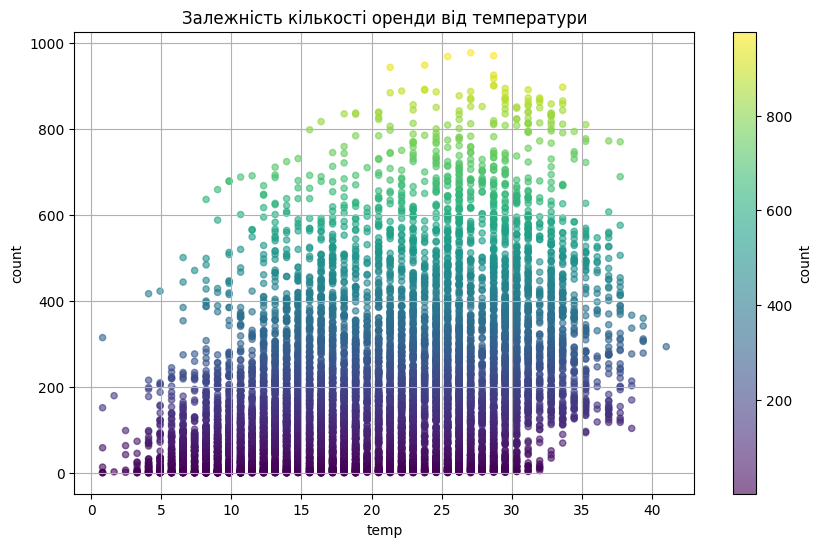

In [80]:
from matplotlib import colors
df.plot.scatter(
    x='temp',
    y='count',
    c='count',
    colormap='viridis',
    title='Залежність кількості оренди від температури',
    figsize=(10, 6),
    alpha=0.6,
    grid=True
);

На графіку чітко видно залежність кількості оренди від температури. Зі зростанням температури від 0°C до 25°C попит на велосипеди впевнено зростає, але після 32-35°C починає помітно падати.
Оптимальна температура - від 20°C до 32°C, є максимально комфортною для поїздок.
Холод (0–10°C) та спека (понад 35°C) - мінімум поїздок

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

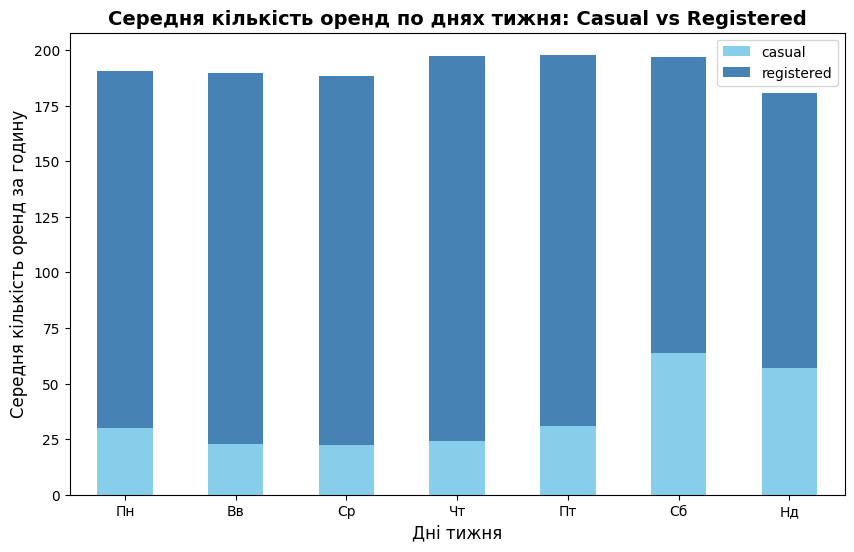

In [86]:
user_compare = df.groupby('weekday_num')[['casual', 'registered']].mean()

user_compare.index = ['Пн', 'Вв', 'Ср', 'Чт', 'Пт', 'Сб', 'Нд']

ax = user_compare.plot.bar(
    stacked=True,
    figsize=(10, 6),
    color=['skyblue', 'steelblue']
)
plt.title('Середня кількість оренд по днях тижня: Casual vs Registered', fontsize=14, fontweight='bold')
plt.xlabel('Дні тижня', fontsize=12)
plt.ylabel('Середня кількість оренд за годину', fontsize=12)
plt.xticks(rotation=0);



1. Найбільша кількість оренд від зареєстрованих користувачів спостерігається у будні дні (з понеділка по п'ятницю), з невеликими піками у четвер та п'ятницю.
2. Зареєстровані користувачі (Registered): використовують велосипеди як щоденний транспорт для поїздок на роботу чи навчання. Тому їхня активність максимальна в робочі дні й помітно падає на вихідних.
3. Випадкові користувачі (Casual): це переважно туристи або містяни, які катаються заради розваги та відпочинку. Їхня частка мінімальна в будні, але стрімко зростає у суботу та неділю, майже компенсуючи вихідний спад постійних клієнтів.
